# **Assessing correlation analysis for MRI metrics and GO pathways in the DLPFC**
## **No superficial white matter**
*Notebook by Melissa Grant-Peters, 11/03/2025*

In this notebook I have aimed to assess the results of the correlative analysis between MRI metrics and GO pathways in the control DLPFC. 

## **Spatial transcriptomic data** 
*Melissa Grant-Peters*

This is the dataset from the spatialDLPFC project, consisting of DLPFC samples from 10 individuals which have been partitioned into anterior, middle and posterior regions. Using the data-driven clustering, we partitioned the coritcal layers in a compromise of data-driven and equivolume by combining certain layers. This resulted in a total of 4 cortical layers plus the white matter. 

### Cell counts per layer
The cell counts for each cell type per layer were estimated using deconvoluted cell2location outputs. 

### GO pathway scores per layer
We scored each layer based on the expression of genes relating to GO pathways of interest. The pathway categories were chosen based on the qMRI metrics available in MRI. The selected terms were: 

- inflammation
- myelin
- lipid
- iron
- mineral 
- neuron cell death

We performed a keyword search for these words among GO pathways, which provided us with lists of genes associated with each pathway. The expression of these genes within each cortical layer was then assessed relative to a random background gene list. 

## **MRI data** 
*George Thomas*

The Weil lab has collected 7T qMRI data from controls which is cortically partitioned into 4 equi-volume layers. This data was subsetted to include Broadman area 46, which corresponds to the DLPFC, into three regions: anterior, middle and posterior, in order to match the public DLPFC data we have access to from the spatialDLPFC project. The qMRI metrics included in this analysis are: 

- QSM - quantitative susceptibility mapping -> ferritin?
- R1 - longitudinal relaxation rate / metric of myelin
- R2* or R2s - transverse relaxation rate / tissue mineralisation, iron
- MTsat - magnetisation transfer / tissue water fraction, could be microstructural measure of atrophy -> extracellular space?


## **Correlation analysis** 
*George Thomas*

The metrics for all cell type scores and iron, lipid, myelin and inflammation pathways were correlated to each of the MRI metrics. 

## **FDR-correction and data visualisation** 
*Melissa Grant-Peters*

The Pearson's-R p-values were then FDR-corrected, with a significance cutoff at 0.01. The goal of this notebook is to visualise and assess features of interest in this analysis, including addressing: 

- Which pathway categories had the most significant pathways for each qMRI metric?
- What was the average qMRI profile for each GO pathway category? 
- What was the distribution of adjusted p-values? 
- Which GO pathways had significant correlations with qMRI metrics?
- Which cell type counts correlated significantly with qMRI metrics? 


# **1.0 Data preparation**

In [387]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
from statsmodels.stats.multitest import fdrcorrection as fdr
import matplotlib as mpl
import numpy as np

In [388]:
df = pd.read_csv('../../processed_data/01b-4layers_withendo/paths_to_keep_all.csv', index_col = 0)

In [389]:
pvals = pd.read_csv('../../plots/02c-4layers_qMRIvsST_withendo_with_PrD/Stats_expanded_pathway_analysis_pval_no_SWM.csv')
pvals = pvals[pvals['Unnamed: 0'].isin(df['pathways_with_min_5_genes'])]

In [390]:
#pvals = pd.read_csv('../../plots/02b-4layers_qMRIvsST_withendo/Stats_expanded_pathway_analysis_pval.csv')
pvals_melt = pd.melt(pvals, id_vars=['Unnamed: 0'], value_vars=['PrD', 'QSM', 'R1', 'R2s', 'MTsat'])
pvals_melt['padj'] = pd.DataFrame(fdr(pvals_melt['value'], alpha=0.05, method='indep', is_sorted=False)).T[1]
pvals_pivot = pd.pivot_table(pvals_melt, values='padj', index=['Unnamed: 0'],
                       columns=['variable'])
pvals_melt['GO_category'] = pvals_melt['Unnamed: 0'].str.split('_', expand = True)[0]
R2 = pd.read_csv('../../plots/02c-4layers_qMRIvsST_withendo_with_PrD/Stats_expanded_pathway_analysis_R2_no_SWM.csv')
R2_melt = pd.melt(R2, id_vars=['Unnamed: 0'], value_vars=['PrD', 'QSM', 'R1', 'R2s', 'MTsat'])
R2_melt.rename(columns={'value' : 'R2'}, inplace = True)
new_df = pd.merge(
    left=pvals_melt, 
    right=R2_melt,
    how='left',
    left_on=['Unnamed: 0', 'variable'],
    right_on=['Unnamed: 0', 'variable'],
)
new_df['sig'] = (new_df['padj']<0.05) & (new_df['R2']>0.85)
new_df = new_df[new_df['Unnamed: 0'].isin(df['pathways_with_min_5_genes'])]

In [391]:
rho_pathways = pd.read_csv('../../plots/02c-4layers_qMRIvsST_withendo_with_PrD/Stats_expanded_pathway_analysis_R2_no_SWM.csv')

In [392]:
new_df[new_df['sig']==True].value_counts('GO_category')

GO_category
lipid           26
myelin           3
inflammation     1
dtype: int64

In [393]:
new_df[(new_df['sig']==True) & (new_df['GO_category']=='inflammation')].value_counts('variable')

variable
R2s    1
dtype: int64

In [394]:
new_df[(new_df['sig']==True) & (new_df['GO_category']=='myelin')].value_counts('variable')

variable
MTsat    1
PrD      1
R2s      1
dtype: int64

In [395]:
new_df[(new_df['sig']==True) & (new_df['GO_category']=='iron')].value_counts('variable')

Series([], dtype: int64)

In [396]:
new_df[(new_df['sig']==True) & (new_df['GO_category']=='lipid')].value_counts('variable')




variable
PrD      7
R2s      7
MTsat    5
R1       4
QSM      3
dtype: int64

In [397]:
# define functions

import requests

def fetch_go_term_name(go_code):
    url = f"https://www.ebi.ac.uk/QuickGO/services/ontology/go/terms/{go_code}"
    response = requests.get(url, headers={"Accept": "application/json"})
    
    if response.status_code == 200:
        data = response.json()
        term_name = data.get("results")[0].get("name")
        return term_name
    else:
        print("Error fetching the GO term")
        return None

# **2.0 Percentage of significant pathways for each pathway type**

### QSM

QSM had the most significant pathways when these related to iron content. 

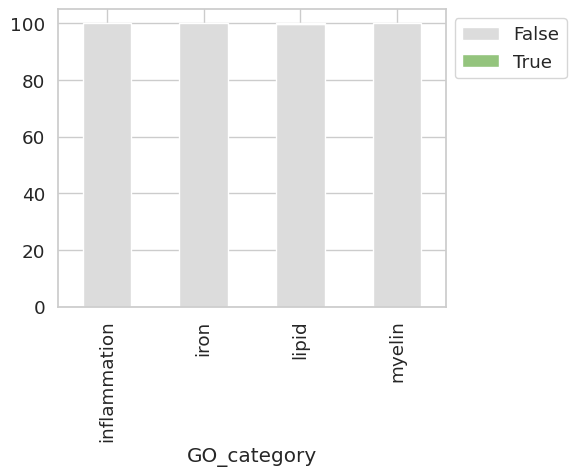

In [398]:
mpl.rcParams['figure.figsize'] = 6, 5

#pvals_melt[['sig', 'GO_category']].plot.bar(x='GO_category', stacked=True, figsize=(8,6))
ax = new_df[new_df['variable']=='QSM'].groupby("GO_category")["sig"].value_counts(normalize=True).mul(100).round(2).unstack().plot(kind='bar', stacked=True, cmap = sns.set_palette(sns.color_palette(['gainsboro','#94C47D'])))

ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()  # Adjust layout to prevent clipping
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/proportion_pathways_QSM.png', bbox_inches = 'tight', dpi = 300)
plt.show()
# R square above value + sig adj pval
# R square distribution#
# How confident are we of the GO pathways (Minimum of more genes)?
# How confident that we are capturing that pathway (% of genes in the pathway? 75%?)?

### PrD

PrD had the most significant pathways when these related to myelin content.

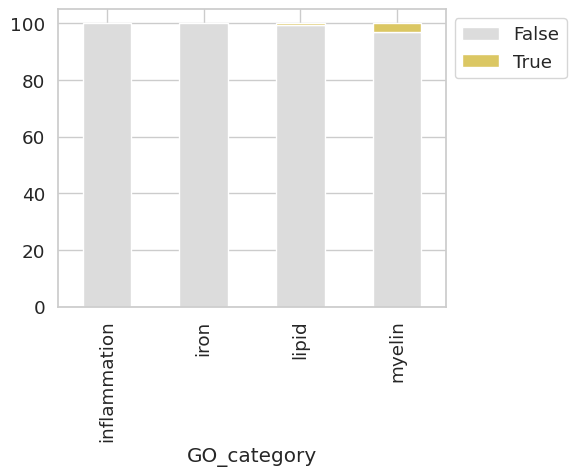

In [399]:
mpl.rcParams['figure.figsize'] = 6, 5

#pvals_melt[['sig', 'GO_category']].plot.bar(x='GO_category', stacked=True, figsize=(8,6))
ax = new_df[new_df['variable']=='PrD'].groupby("GO_category")["sig"].value_counts(normalize=True).mul(100).round(2).unstack().plot(kind='bar', stacked=True, cmap = sns.set_palette(sns.color_palette(['gainsboro','#DBC763'])))

ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()  # Adjust layout to prevent clipping
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/proportion_pathways_QSM.png', bbox_inches = 'tight', dpi = 300)
plt.show()

### R1

R1 had the most significant pathways when these related to lipid content.

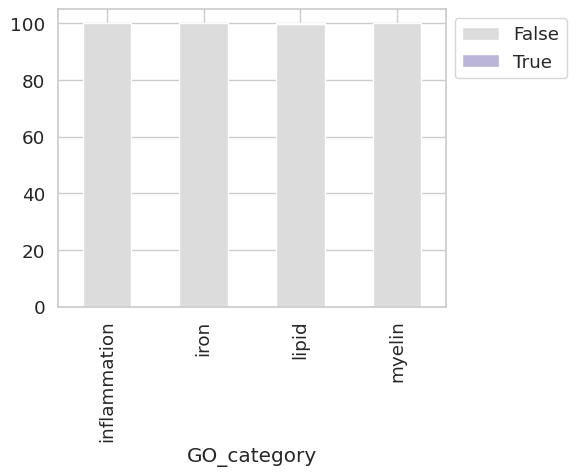

In [400]:
ax = new_df[new_df['variable']=='R1'].groupby("GO_category")["sig"].value_counts(normalize=True).mul(100).round(2).unstack().plot(kind='bar', stacked=True, cmap = sns.set_palette(sns.color_palette(['gainsboro','#BAB4D8'])))

ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()  # Adjust layout to prevent clipping
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/proportion_pathways_R1.png', bbox_inches = 'tight', dpi = 300)
plt.show()

### R2s

R2s had comparable correlations with inflammation, iron and lipid. 

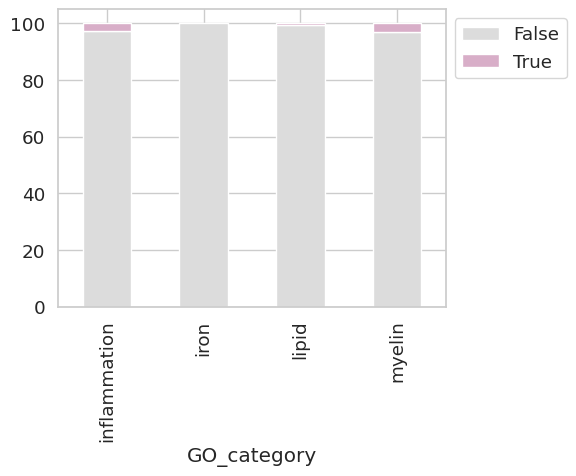

In [401]:
ax = new_df[new_df['variable']=='R2s'].groupby("GO_category")["sig"].value_counts(normalize=True).mul(100).round(2).unstack().plot(kind='bar', stacked=True, cmap = sns.set_palette(sns.color_palette(['gainsboro','#D8AEC8'])))
ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()  # Adjust layout to prevent clipping
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/proportion_pathways_R2s.png', bbox_inches = 'tight', dpi = 300)
plt.show()

### MTsat

MTsat had comparable correlations with inflammation and lipid. 

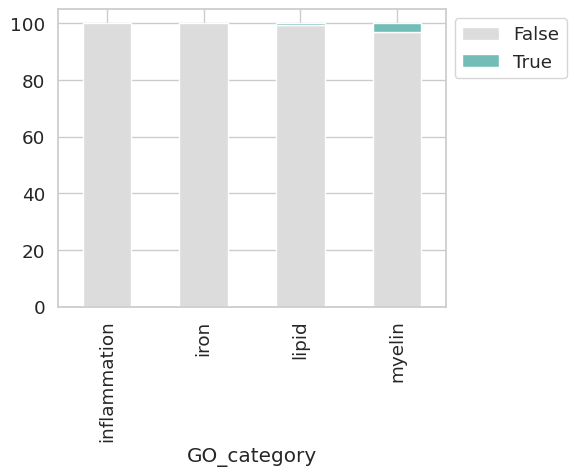

In [402]:
ax = new_df[new_df['variable']=='MTsat'].groupby("GO_category")["sig"].value_counts(normalize=True).mul(100).round(2).unstack().plot(kind='bar', stacked=True, cmap = sns.set_palette(sns.color_palette(['gainsboro','#72BEB7'])))

ax.legend(loc='upper left', bbox_to_anchor=(1, 1))
plt.tight_layout()  # Adjust layout to prevent clipping
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/proportion_pathways_MTsat.png', bbox_inches = 'tight', dpi = 300)
plt.show()

# **4.0 Assessing correlations per pathway type**

## 4.1 Inflammation

We have found that several inflammation pathways have significant positive correlations with multiple qMRI metrics and one had a negative correlation. We found that pathways associated with very specific events in the inflammatory cascade (e.g. JNK cascade, p38MAPK cascade) were less likely to correlate, while more generic inflammation-associated pathways (e.g. inflammatory response, acute inflammatory response, chronic inflammatory response) were more likely to have significant relationships. 

In [403]:
rho_pathways.value_counts('GO.category')

GO.category
lipid           2112
inflammation      82
iron              81
myelin            42
dtype: int64

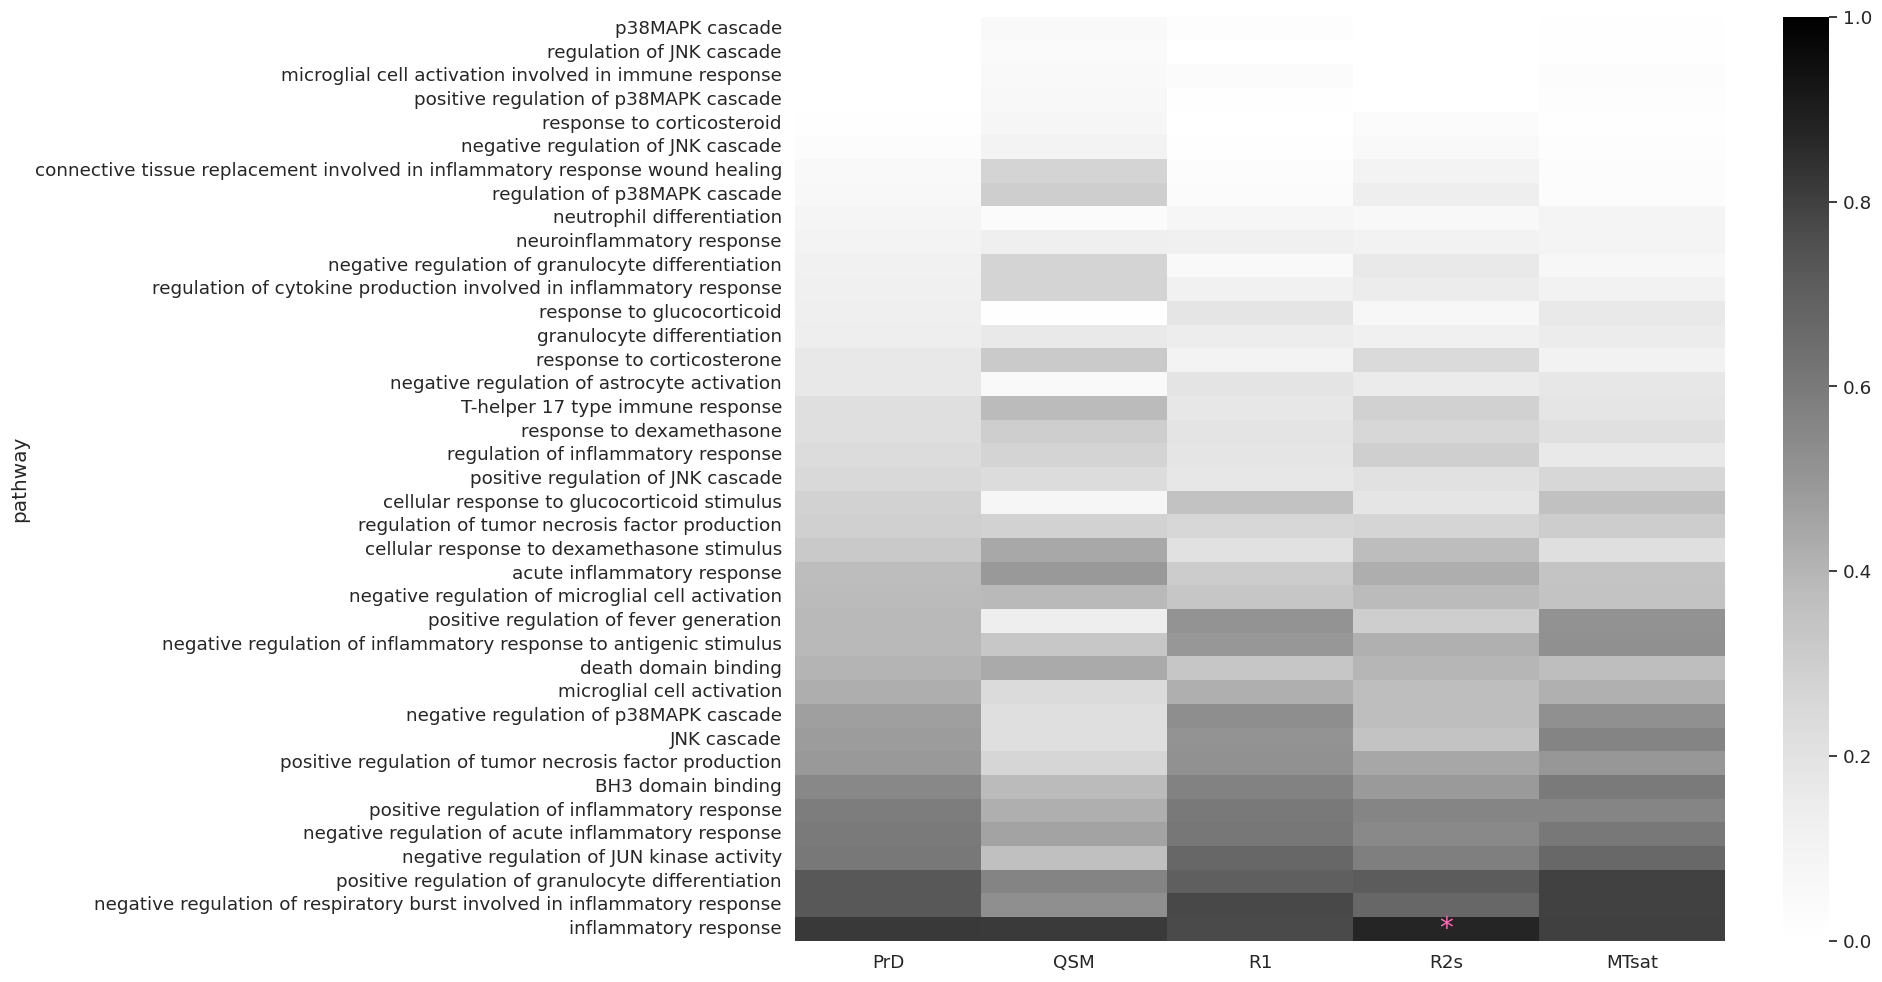

Index(['inflammatory response'], dtype='object', name='pathway')


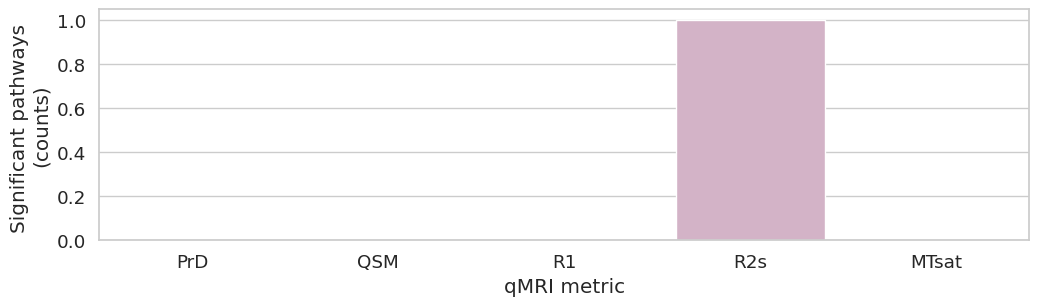

In [404]:
sns.set(font_scale=1.2)

inflammation = rho_pathways[rho_pathways['GO.category']=='inflammation']
inflammation = inflammation[inflammation['Unnamed: 0'].isin(df['pathways_with_min_5_genes'])]
inflammation.sort_values(by =['PrD'], inplace = True)

#Prepare pathway names
pathway_IDs = inflammation['Unnamed: 0'].str.split('_', expand = True)[1]
pathway_name = []
for row in pathway_IDs:
    GO_ID = 'GO:'+row.split('GO')[1]
    term_name = fetch_go_term_name(GO_ID)
    pathway_name.append(term_name)
    
inflammation['pathway'] = pathway_name
inflammation.set_index('pathway', inplace = True)


fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(inflammation[['PrD', 'QSM','R1','R2s','MTsat']], cmap = 'Greys', vmin = 0, vmax = 1)
inflam_pvals = pvals_pivot[pvals_pivot.index.isin(inflammation['Unnamed: 0'])]
inflam_pvals = inflam_pvals.loc[list(inflammation['Unnamed: 0'])]
inflam_pvals = inflam_pvals[['PrD', 'QSM','R1','R2s','MTsat']]
sig_paths = []
sig_matrix = np.full_like(inflam_pvals, 0)
for i in range(inflammation[['PrD', 'QSM','R1','R2s','MTsat']].shape[0]):
    for j in range(inflammation[['PrD', 'QSM','R1','R2s','MTsat']].shape[1]):
        if inflam_pvals.iloc[i,j]<0.05 and inflammation[['PrD', 'QSM','R1','R2s','MTsat']].iloc[i,j]>0.85:
            value = "*"
            #value = '{:.2f}\n(p={:.2e})'.format(piv_counts.iloc[i, j], pvals.iloc[i, j])
            ax.text(j+0.5, i+0.5, value, ha='center', va='center', fontsize=20, color='hotpink')
            sig_paths.append(inflam_pvals.index[i])
            sig_matrix[i,j] = 1
            
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/inflammation_visualisation_heatmap.png', bbox_inches = 'tight', dpi = 300)
plt.show()
#

print(inflammation[inflammation['Unnamed: 0'].isin(np.unique(sig_paths))].index)
from matplotlib import rcParams

# figure size in inches
rcParams['figure.figsize'] = 12, 3
sns.set_style("whitegrid")

total_sig_paths = pd.DataFrame(sig_matrix, columns = list(inflam_pvals.columns), index = list(inflam_pvals.index))
total_sig_paths = total_sig_paths.sum(axis = 0).to_frame().reset_index()
total_sig_paths = total_sig_paths.rename(columns = {'index':'metric', 0:'count'})
sns.barplot(x = total_sig_paths['metric'], y = total_sig_paths['count'], palette = sns.set_palette(['#DBC763','#94C47D','#BAB4D8','#D8AEC8','#72BEB7']))
plt.xlabel('qMRI metric')
plt.ylabel('Significant pathways \n(counts)')
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/barplot_inflammation_visualisation_heatmap.png', bbox_inches = 'tight', dpi = 300)
plt.show()
all_sig = total_sig_paths.rename(columns = {'count':'Inflammation'})

In [405]:
import numpy as np
np.unique(sig_paths)

array(['inflammation_GO0006954'], dtype='<U22')

In [406]:
total_sig_paths

,metric,count
0,PrD,0.0
1,QSM,0.0
2,R1,0.0
3,R2s,1.0
4,MTsat,0.0


## 4.2 Myelin


We have found that several myelin pathways have significant positive or negative correlations with qMRI metrics. Pathways associated with myelin maintenance tended to have negative correlations with qMRI metrics, whilst generic pathways associated with myelin (myelination, structural constituent of myelin sheath, positive regulation of myelination) tended to have positive correlations with R1, R2* and MTsat. 

In [407]:
myelin = rho_pathways[rho_pathways['GO.category']=='myelin']
#inflammation = inflammation.merge(terms, left_on = 'Unnamed: 0', right_on = 'GO_term', how = 'inner')

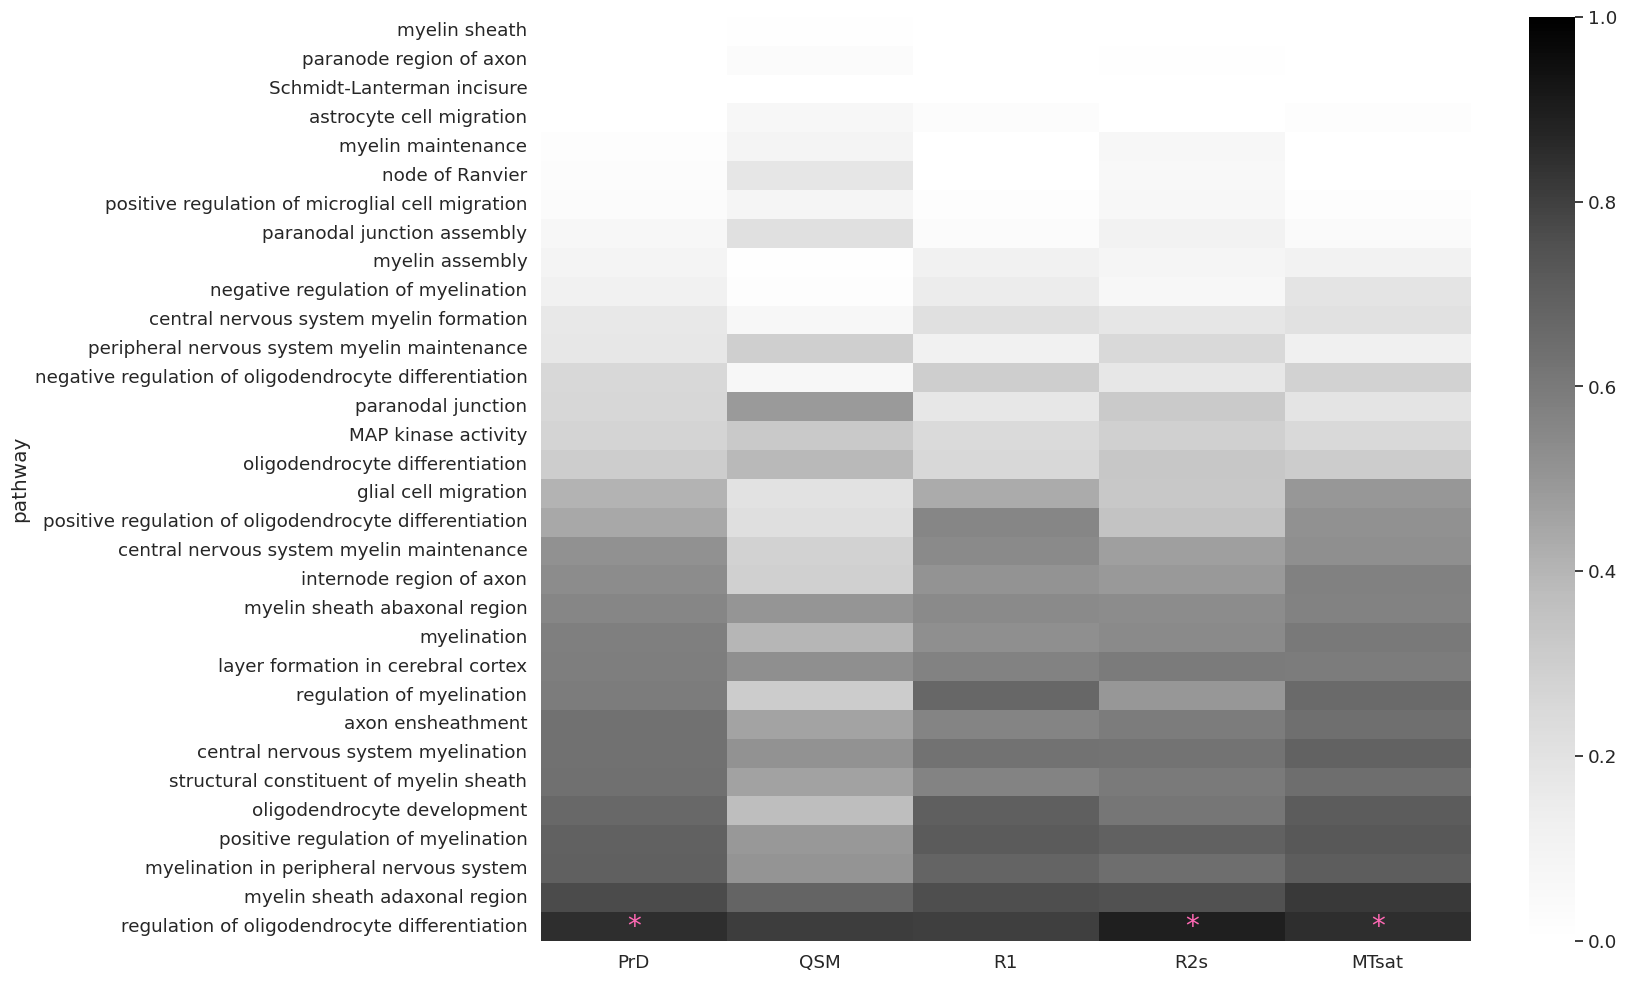

Index(['regulation of oligodendrocyte differentiation'], dtype='object', name='pathway')


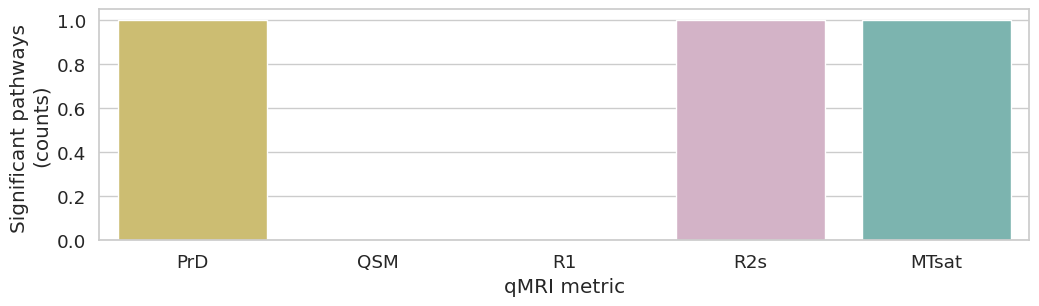

In [408]:
#terms
myelin = rho_pathways[rho_pathways['GO.category']=='myelin']
myelin = myelin[myelin['Unnamed: 0'].isin(df['pathways_with_min_5_genes'])]
myelin.sort_values(by =['PrD'], inplace = True)

#Prepare pathway names
pathway_IDs = myelin['Unnamed: 0'].str.split('_', expand = True)[1]
pathway_name = []
for row in pathway_IDs:
    GO_ID = 'GO:'+row.split('GO')[1]
    term_name = fetch_go_term_name(GO_ID)
    pathway_name.append(term_name)
    
myelin['pathway'] = pathway_name
myelin.set_index('pathway', inplace = True)


fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(myelin[['PrD', 'QSM','R1','R2s','MTsat']], cmap = 'Greys', vmin = 0, vmax = 1)
myelin_pvals = pvals_pivot[pvals_pivot.index.isin(myelin['Unnamed: 0'])]
myelin_pvals = myelin_pvals.loc[list(myelin['Unnamed: 0'])]
myelin_pvals = myelin_pvals[['PrD', 'QSM','R1','R2s','MTsat']]
sig_paths = []
sig_matrix = np.full_like(myelin_pvals, 0)
for i in range(myelin[['PrD', 'QSM','R1','R2s','MTsat']].shape[0]):
    for j in range(myelin[['PrD', 'QSM','R1','R2s','MTsat']].shape[1]):
        if myelin_pvals.iloc[i,j]<0.05 and myelin[['PrD', 'QSM','R1','R2s','MTsat']].iloc[i,j]>0.85:
            value = "*"
            #value = '{:.2f}\n(p={:.2e})'.format(piv_counts.iloc[i, j], pvals.iloc[i, j])
            ax.text(j+0.5, i+0.5, value, ha='center', va='center', fontsize=20, color='hotpink')
            sig_paths.append(myelin_pvals.index[i])
            sig_matrix[i,j] = 1
            
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/myelin_visualisation_heatmap.png', bbox_inches = 'tight', dpi = 300)
plt.show()
print(myelin[myelin['Unnamed: 0'].isin(np.unique(sig_paths))].index)

# figure size in inches
rcParams['figure.figsize'] = 12, 3
sns.set_style("whitegrid")

total_sig_paths = pd.DataFrame(sig_matrix, columns = list(myelin_pvals.columns), index = list(myelin_pvals.index))
total_sig_paths = total_sig_paths.sum(axis = 0).to_frame().reset_index()
total_sig_paths = total_sig_paths.rename(columns = {'index':'metric', 0:'count'})
sns.barplot(x = total_sig_paths['metric'], y = total_sig_paths['count'], palette = sns.set_palette(['#DBC763','#94C47D','#BAB4D8','#D8AEC8','#72BEB7']))
plt.xlabel('qMRI metric')
plt.ylabel('Significant pathways \n(counts)')
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/barplot_myelin_visualisation_heatmap.png', bbox_inches = 'tight', dpi = 300)
plt.show()

all_sig = all_sig.merge(total_sig_paths.rename(columns = {'count':'Myelin'}), left_on = 'metric', right_on = 'metric', how = 'inner')



## 4.3 Iron

We have found that several iron pathways more commonly have negative correlations with qMRI metrics, including iron-sulfur cluster binding, heme biosynthetic processresponse to iron ion starvation, all of which are processes reducing free iron in tissue. Positively correlated pathways included response to iron ion, ferrous iron transmembrane transporter activity. As predicted by the relationship between QSM and ferritin, this category had the most significant correlation events with the QSM metric. 


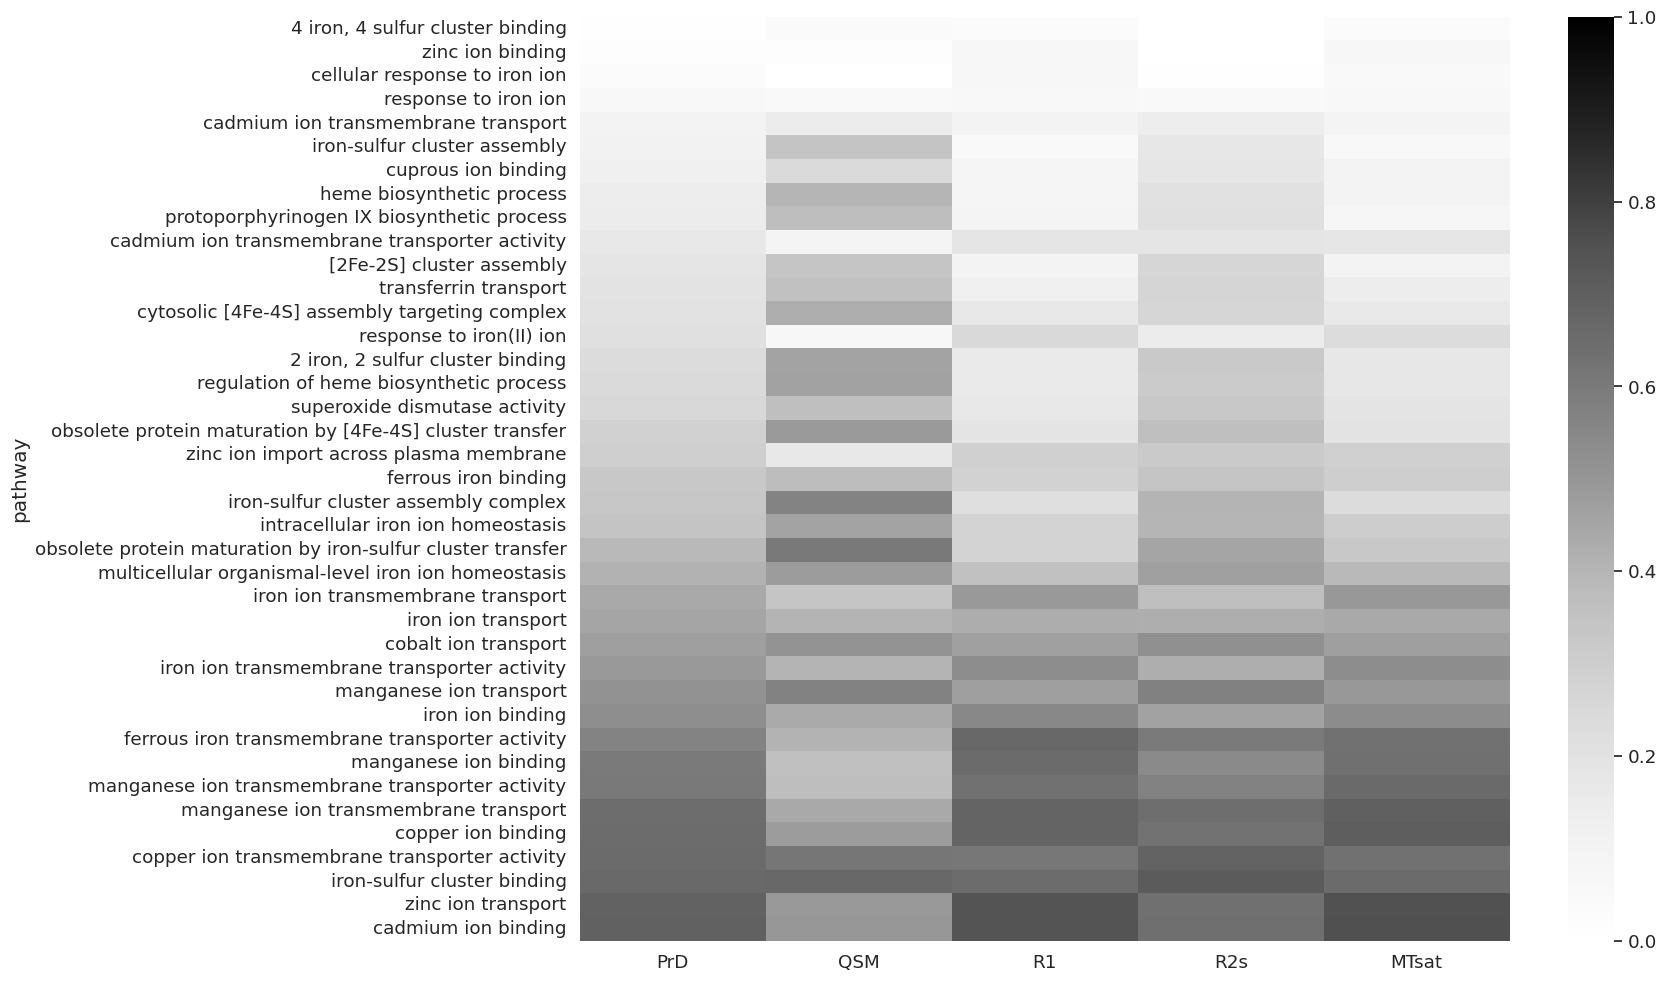

Index([], dtype='object', name='pathway')


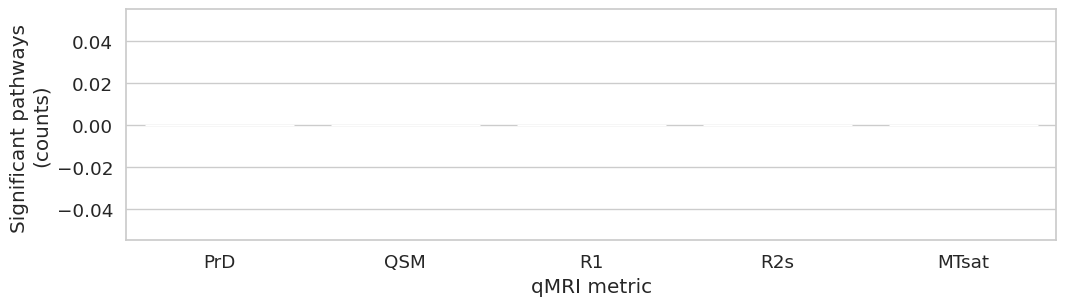

In [409]:
#terms
iron = rho_pathways[rho_pathways['GO.category']=='iron']
iron = iron[iron['Unnamed: 0'].isin(df['pathways_with_min_5_genes'])]
iron.sort_values(by =['PrD'], inplace = True)

#Prepare pathway names
pathway_IDs = iron['Unnamed: 0'].str.split('_', expand = True)[1]
pathway_name = []
for row in pathway_IDs:
    GO_ID = 'GO:'+row.split('GO')[1]
    term_name = fetch_go_term_name(GO_ID)
    pathway_name.append(term_name)
    
iron['pathway'] = pathway_name
iron.set_index('pathway', inplace = True)

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(iron[['PrD', 'QSM','R1','R2s','MTsat']], cmap = 'Greys', vmin = 0, vmax = 1)
iron_pvals = pvals_pivot[pvals_pivot.index.isin(iron['Unnamed: 0'])]
iron_pvals = iron_pvals.loc[list(iron['Unnamed: 0'])]
iron_pvals = iron_pvals[['PrD', 'QSM','R1','R2s','MTsat']]
sig_paths = []
sig_matrix = np.full_like(iron_pvals, 0)
for i in range(iron[['PrD', 'QSM','R1','R2s','MTsat']].shape[0]):
    for j in range(iron[['PrD', 'QSM','R1','R2s','MTsat']].shape[1]):
        if iron_pvals.iloc[i,j]<0.05 and iron[['PrD', 'QSM','R1','R2s','MTsat']].iloc[i,j]>0.85:
            value = "*"
            #value = '{:.2f}\n(p={:.2e})'.format(piv_counts.iloc[i, j], pvals.iloc[i, j])
            ax.text(j+0.5, i+0.5, value, ha='center', va='center', fontsize=16, color='hotpink')
            sig_paths.append(iron_pvals.index[i])
            sig_matrix[i,j] = 1

#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/iron_visualisation_heatmap.png', bbox_inches = 'tight', dpi = 300)
plt.show()
print(iron[iron['Unnamed: 0'].isin(np.unique(sig_paths))].index)

total_sig_paths = pd.DataFrame(sig_matrix, columns = list(iron_pvals.columns), index = list(iron_pvals.index))
total_sig_paths = total_sig_paths.sum(axis = 0).to_frame().reset_index()
total_sig_paths = total_sig_paths.rename(columns = {'index':'metric', 0:'count'})
sns.barplot(x = total_sig_paths['metric'], y = total_sig_paths['count'], palette = sns.set_palette(['#DBC763','#94C47D','#BAB4D8','#D8AEC8','#72BEB7']))
plt.xlabel('qMRI metric')
plt.ylabel('Significant pathways \n(counts)')
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/barplot_iron_visualisation_heatmap.png', bbox_inches = 'tight', dpi = 300)
plt.show()
all_sig = all_sig.merge(total_sig_paths.rename(columns = {'count':'Iron'}), left_on = 'metric', right_on = 'metric', how = 'inner')

## 4.4 Lipid

This category had the most pathways tested and had strong correlations with the most qMRI metrics, especially R1. 

In [410]:
lipid = rho_pathways[rho_pathways['GO.category'].isin(df['pathways_with_min_5_genes'])]
lipid = rho_pathways[rho_pathways['GO.category']=='lipid']
lipid

,Unnamed: 0,QSM,R1,R2s,PrD,MTsat,GO.category
163,lipid_GO0000015,0.217489,0.056734,0.131351,0.094462,0.073871,lipid
164,lipid_GO0000026,0.402216,0.460748,0.474620,0.455450,0.433975,lipid
165,lipid_GO0000030,0.421720,0.475886,0.478430,0.474914,0.475605,lipid
166,lipid_GO0000033,0.365906,0.227720,0.298170,0.259812,0.259854,lipid
167,lipid_GO0000038,0.303557,0.239562,0.248781,0.323813,0.309113,lipid
...,...,...,...,...,...,...,...
2270,lipid_GO2000969,0.344538,0.603875,0.441670,0.507805,0.601086,lipid
2271,lipid_GO2001140,0.569767,0.636423,0.592636,0.610524,0.660780,lipid
2272,lipid_GO2001247,0.669441,0.609741,0.688880,0.650250,0.616856,lipid
2273,lipid_GO2001259,0.076502,0.000349,0.014936,0.005024,0.000050,lipid


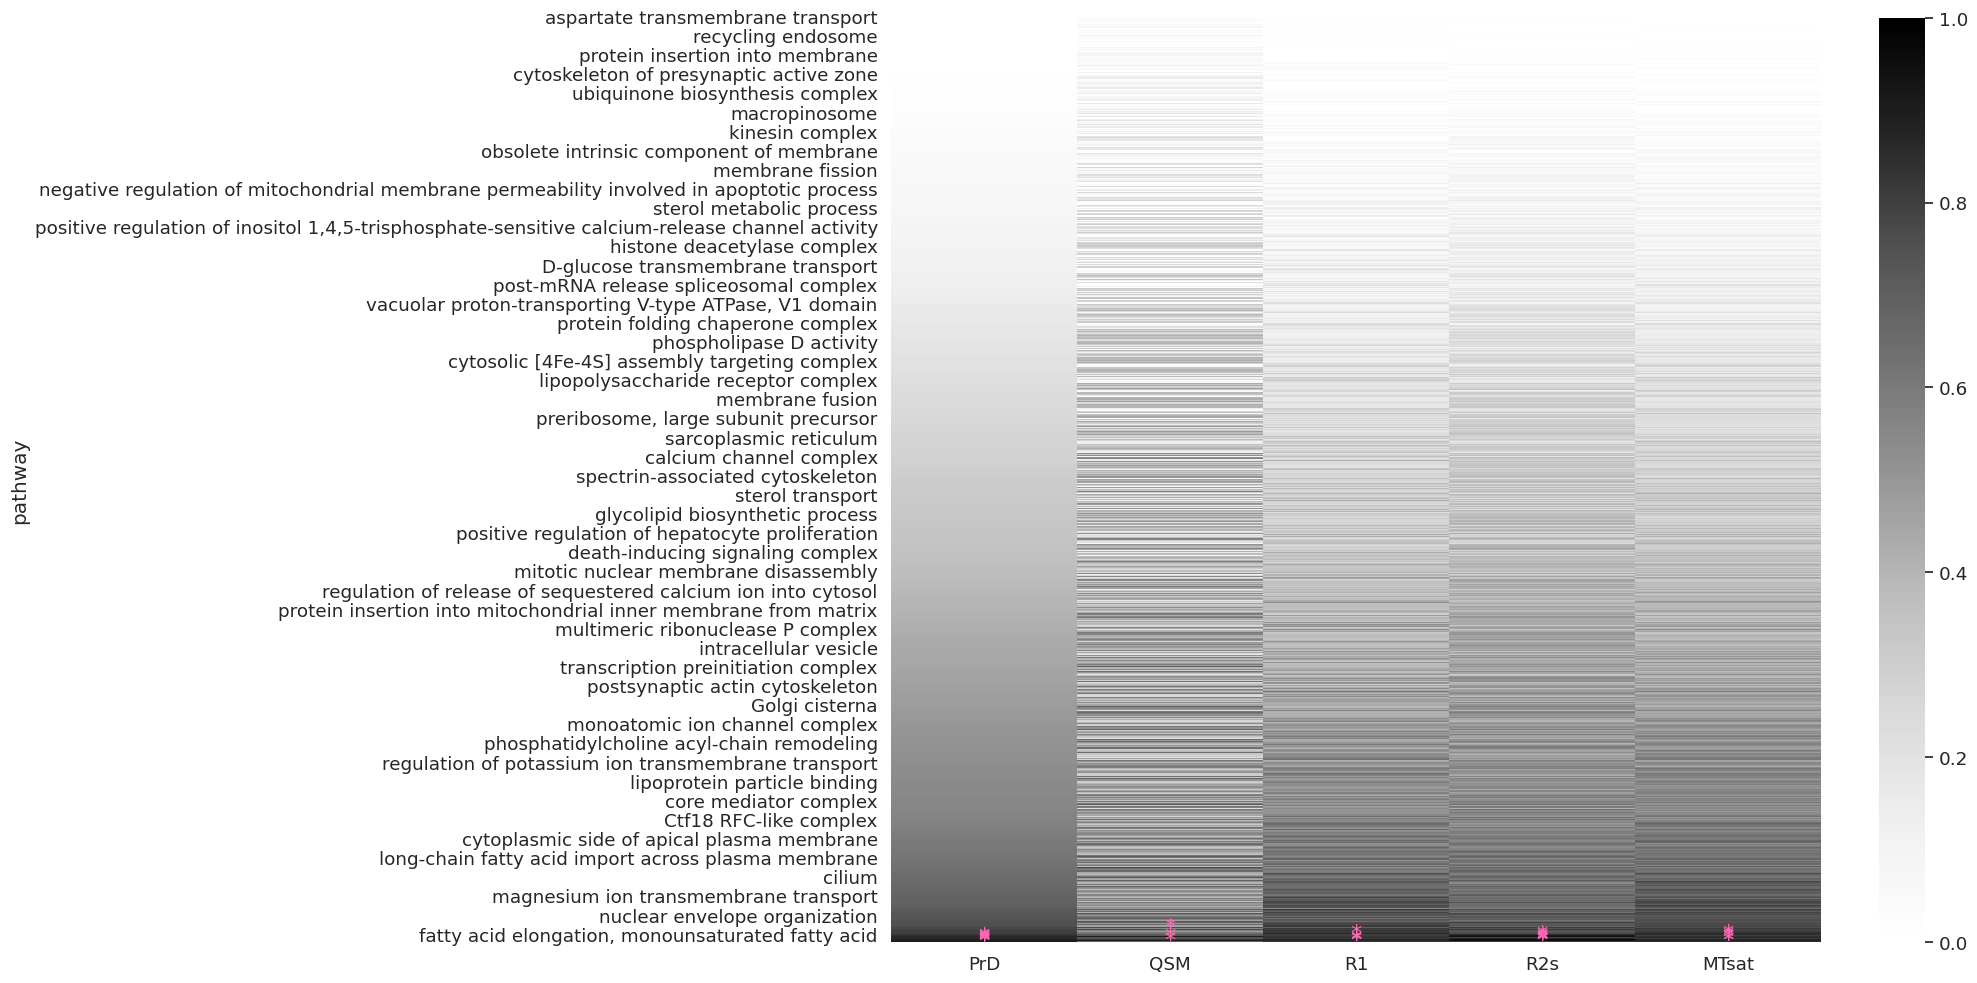

Index(['U2-type catalytic step 2 spliceosome', 'paraspeckles',
       'glycolipid binding', 'obsolete integral component of Golgi membrane',
       'fatty acid elongation, monounsaturated fatty acid',
       'galactosylceramide biosynthetic process',
       'phosphatidylinositol-3-phosphate biosynthetic process',
       'phosphatidylserine floppase activity',
       'release of sequestered calcium ion into cytosol by sarcoplasmic reticulum',
       'fatty acid metabolic process', 'response to vitamin D',
       'phospholipid-translocating ATPase complex'],
      dtype='object', name='pathway')


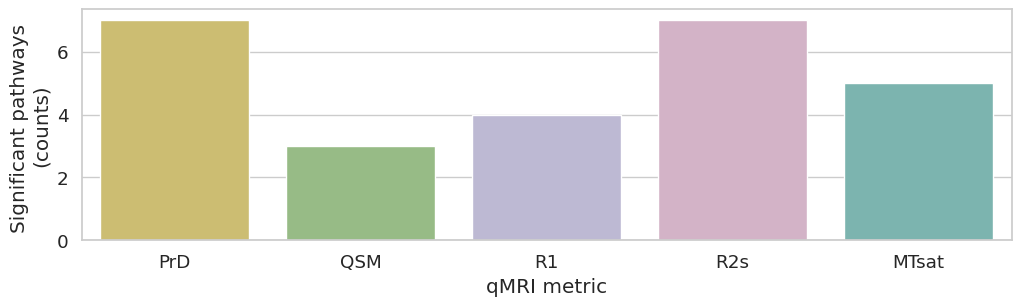

In [411]:
#Reorder data and pvalues to match
lipid = rho_pathways[rho_pathways['GO.category']=='lipid']
lipid = lipid[lipid['Unnamed: 0'].isin(df['pathways_with_min_5_genes'])]
lipid.sort_values(by =['PrD'], inplace = True)

#Prepare pathway names
pathway_IDs = lipid['Unnamed: 0'].str.split('_', expand = True)[1]
pathway_name = []
for row in pathway_IDs:
    GO_ID = 'GO:'+row.split('GO')[1]
    term_name = fetch_go_term_name(GO_ID)
    pathway_name.append(term_name)
    
lipid['pathway'] = pathway_name
lipid.set_index('pathway', inplace = True)

fig, ax = plt.subplots(figsize=(15, 12))
sns.heatmap(lipid[['PrD', 'QSM','R1','R2s','MTsat']], cmap = 'Greys', vmin = 0, vmax = 1)
lipid_pvals = pvals_pivot[pvals_pivot.index.isin(lipid['Unnamed: 0'])]
lipid_pvals = lipid_pvals.loc[list(lipid['Unnamed: 0'])]
lipid_pvals = lipid_pvals[['PrD', 'QSM','R1','R2s','MTsat']]


sig_paths = []
sig_matrix = np.full_like(lipid_pvals, 0)
for i in range(lipid[['PrD', 'QSM','R1','R2s','MTsat']].shape[0]):
    for j in range(lipid[['PrD', 'QSM','R1','R2s','MTsat']].shape[1]):
        if lipid_pvals.iloc[i,j]<0.05 and lipid[['PrD', 'QSM','R1','R2s','MTsat']].iloc[i,j]>0.85:
            value = "*"
            #value = '{:.2f}\n(p={:.2e})'.format(piv_counts.iloc[i, j], pvals.iloc[i, j])
            ax.text(j+0.5, i+0.5, value, ha='center', va='center', fontsize=16, color='hotpink')
            sig_paths.append(lipid_pvals.index[i])
            sig_matrix[i,j] = 1
            
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/lipid_visualisation_heatmap.png', bbox_inches = 'tight', dpi = 300)
plt.show()
print(lipid[lipid['Unnamed: 0'].isin(np.unique(sig_paths))].index)

# figure size in inches
rcParams['figure.figsize'] = 12, 3
sns.set_style("whitegrid")

total_sig_paths = pd.DataFrame(sig_matrix, columns = list(lipid_pvals.columns), index = list(lipid_pvals.index))
total_sig_paths = total_sig_paths.sum(axis = 0).to_frame().reset_index()
total_sig_paths = total_sig_paths.rename(columns = {'index':'metric', 0:'count'})
sns.barplot(x = total_sig_paths['metric'], y = total_sig_paths['count'], palette = sns.set_palette(['#DBC763','#94C47D','#BAB4D8','#D8AEC8','#72BEB7']))
plt.xlabel('qMRI metric')
plt.ylabel('Significant pathways \n(counts)')
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/barplot_lipid_visualisation_heatmap.png', bbox_inches = 'tight', dpi = 300)
plt.show()
all_sig = all_sig.merge(total_sig_paths.rename(columns = {'count':'Lipid'}), left_on = 'metric', right_on = 'metric', how = 'inner')

# **5.0 GO pathway categories vs MRI metrics**

The goal of this analysis was to summarise which MRI metrics tended to be more significant for each GO pathway. For this, we calculated the proportion of significant pathways per category. 

- Myelin and lipid pathways tended to have higher correlations for R1, R2* and MTsat, and low correlations with QSM
- Inflammation pathways had very high correlations with R1, R2* and MTsat and intermediary relationship with QSM. The latter metric may associated with the iron redistribution in a context of inflammation. 
- Iron had the most distinctive signature, with lower correlation frequency with R1, R2* and MTsat, but the highest correlation with QSM

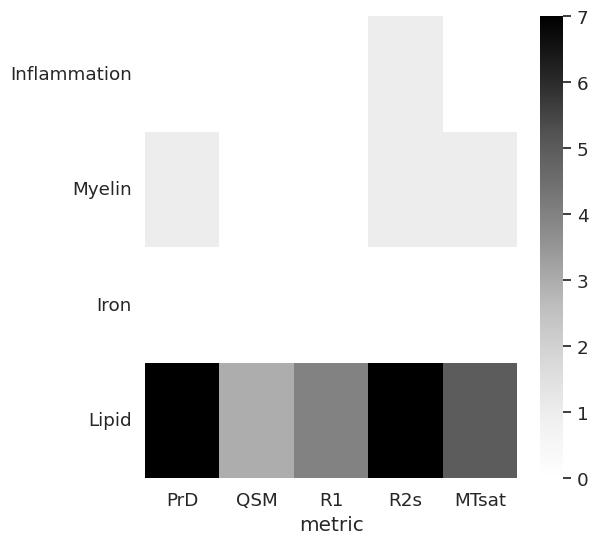

In [412]:
rcParams['figure.figsize'] = 6, 6

sns.heatmap(all_sig.set_index('metric').T, vmin = 0, cmap = 'Greys')
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/pathwaygroup_per_MRImetric_heatmap.png', bbox_inches = 'tight', dpi = 300)
plt.yticks(rotation=0) 
plt.show()


# **6.0 MRI relationship with cell type counts**

We show based on our previous analyses that the metrics with strongest relationships with myelin and lipid associated pathways were MTsat, R1 and R2s. We test to see if this is also reflected in the estimated cell type counts. Indeed, we find that Oligodendrocyte counts, a cell type which produces myelin in the CNS and has a high lipid content, correlate strongly with MTsat, R1 and R2s counts. Notably, counts of microglia were not sufficient to correlate with inflammation-associated signals. This may relate to the heterogeneous nature of microglial population, which means they inherently have more variable biochemical profiles. 

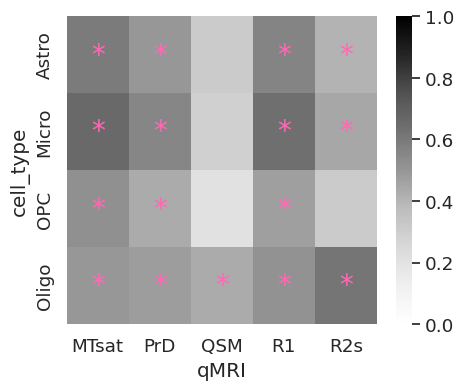

In [413]:
counts = pd.read_csv('../../plots/02c-4layers_qMRIvsST_withendo_with_PrD/Stats_control_qMRI_vs_cell_count_no_SWM.csv')

import matplotlib.pyplot as plt
piv_counts = pd.pivot_table(counts, values='R2', index=['cell_type'],
                       columns=['qMRI'], aggfunc="sum")
pvals = pd.pivot_table(counts, values='corr_p', index=['cell_type'],
                       columns=['qMRI'], aggfunc="sum")
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(piv_counts,ax=ax, cmap = 'Greys', vmin = 0, vmax = 1)
for i in range(piv_counts.shape[0]):
    for j in range(piv_counts.shape[1]):
        if pvals.iloc[i,j]<0.05:
            value = "*"
            #value = '{:.2f}\n(p={:.2e})'.format(piv_counts.iloc[i, j], pvals.iloc[i, j])
            ax.text(j+0.5, i+0.5, value, ha='center', va='center', fontsize=20, color='hotpink')
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/cellcount_heatmap_summary.png', bbox_inches = 'tight', dpi = 300)
plt.show()

# **7.0 Conclusions and future work**

Our analysis shows that qMRI metrics have significant correlation relationships with transcriptomic pathways. 

- **Validation of QSM metric** - Since QSM signals are considered a metric for ferritin, our validation shows that iron-associated pathways have significant relationships with this metric more frequently and specifically than other GO terms. 
- **Inflammation is capturable in qMRI, and is distinct from lipid, myelin and iron content** - Like iron, it has a higher QSM correlation, but unlike iron has higher correlations with R1, R2s* and MTsat. This may relate to hypercellularity increasing lipid content in a region, while iron redistribution into macrophages and microglia affect QSM. 
- **It is challenging to distinguish lipid and myelin with qMRI metrics** - There is a small difference in the rate of correlation with QSM, but this is hard to explain. Oligodendrocytes normally store ferritin at very high rates, but this is not evident in the relationships we see. 


# **Appendix**

Preliminary analysis from George shows that the qMRI data from PD captures a drop in the MTsat levels at the layer closest to the pial surface, not observed in any other layer. Importantly, this shift is **only** on this metric, and in no other metric. A trend in R1 drop could also be seen, even though this was not significant. Based on this I decided to verify which pathways we assessed that had a lower MTsat measure than R2* measure by at least 5%. I identified a total of 116 pathways, of which 6 were associated with inflammation (especially regulation of inflammation), one was an offspring of a myelin-associated term and 99 associated with lipids or offspring terms from a lipid pathway. This suggested to us the abnormality we observed was more likely to be lipid associated. We filtered the significant pathways to only include those directly associated with lipid, by filtering descriptions that had the word 'lipid'. Among these was the pathway "glycosphingolipid biosynthetic process". We are currently assessing whether glycosphingolipid levels in the surface and the deep cortex to verify whether this may contribute to the  shift. 

In [414]:
rho_pathways = pd.read_csv('../../plots/02c-4layers_qMRIvsST_withendo_with_PrD/Stats_expanded_pathway_analysis_rho_no_SWM.csv')
sig = list(new_df[new_df['sig']==1]['Unnamed: 0'])
sig_rho = rho_pathways[rho_pathways['Unnamed: 0'].isin(sig)]
pathways = sig_rho[sig_rho['MTsat']<(sig_rho['R2s']-0.05)]
pathway_IDs = pathways['Unnamed: 0'].str.split('_', expand = True)[1]
pathway_name = []
for row in pathway_IDs:
    GO_ID = 'GO:'+row.split('GO')[1]
    term_name = fetch_go_term_name(GO_ID)
    pathway_name.append(term_name)

print(len(pathway_name))
pathways['pathway_description'] = pathway_name
#lipid_associated = pathways[pathways['pathway_description'].isin(['positive regulation of phospholipid translocation','positive regulation of lipid catabolic process', 'lipid phosphorylation', 'glycosphingolipid biosynthetic process', 'calcium-dependent phospholipid binding'])]

3


/tmp/ipykernel_472869/3217387758.py:13: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  pathways['pathway_description'] = pathway_name


In [415]:
pathways

,Unnamed: 0,QSM,R1,R2s,PrD,MTsat,GO.category,pathway_description
565,lipid_GO0006682,0.951892,0.910568,0.966733,-0.927791,0.914579,lipid,galactosylceramide biosynthetic process
1227,lipid_GO0034625,0.853615,0.896039,0.953213,-0.920185,0.897602,lipid,"fatty acid elongation, monounsaturated fatty acid"
1365,lipid_GO0042382,-0.803685,-0.929785,-0.874308,0.899063,-0.932183,lipid,paraspeckles


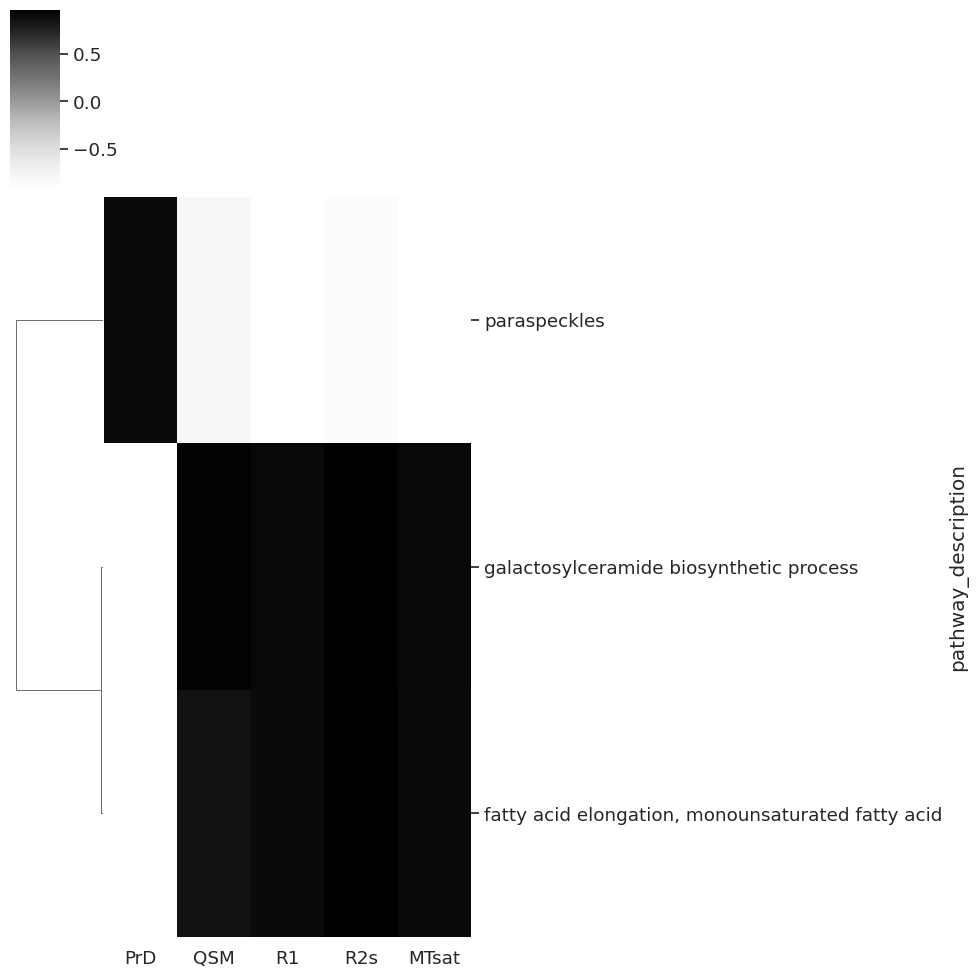

In [416]:
rcParams['figure.figsize'] = 4, 5

sns.clustermap(pathways.set_index('pathway_description')[['PrD','QSM','R1','R2s','MTsat']], cmap = 'Greys', col_cluster = False)
#plt.savefig('../../plots/01b-4layers_withendo/06-pathway_vis/rho_analysis_pathways.png', bbox_inches = 'tight', dpi = 300)
plt.show()

In [417]:
all_sig_pathways = ['inflammation_GO0006954','myelin_GO0014003', 'myelin_GO0019911', 'myelin_GO0031643', 'myelin_GO0033269', 'myelin_GO0042552','lipid_GO0005227', 'lipid_GO0005778', 'lipid_GO0030148', 'lipid_GO0030658', 'lipid_GO0030660', 'lipid_GO0032580', 'lipid_GO0034379', 'lipid_GO1902388']
full_pathway_name = []
for p in all_sig_pathways:
    form_p = 'GO:'+(p.split('GO')[1])
    term_name = fetch_go_term_name(form_p)
    full_pathway_name.append(term_name)